# 四属性 API 辅助检视：描述性结果

本 notebook 从 `../results/aggregate_results.json` 读取可复算汇总，展示各属性、各策略、各构念的评分与偏好。当前数据来自 **参与者1（P001），n=1**。四属性是同一人的四组判断，不能计作四人；32 道任务也不是32份独立问卷。

- 原始问卷为 **attribute-summary-feedback-v2**；P001 并未重新填写 v3。
- 原始 tone 的无法判断由参与者明确更正为同时偏好 **N 与 S**。每项各计1票，原下载与更正记录均保留。其余80项评分原样。
- 输入与澄清由助手按用户授权代拟，反馈由参与者填写；这是绕过 STT 的 API 辅助检视，不是已完成的 VR 正式实验。
- 音频产生于此次后续澄清修复之前，不能代表新修复效果。本分析不重放模型、不重评原问卷。
- 分别展示 A0–A4；不相加为 SUS/SASSI 或其它标准总分，不做 n=1 显著性推断。无法判断与未提交不转成0分。
- 不同 batch、源问卷版本、task releases 分 cohort 展示，不能混为独立样本。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline

candidates = [Path('../results/aggregate_results.json'), Path('Experiments/results/aggregate_results.json'), Path('results/aggregate_results.json')]
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Run from Experiments/analysis or the repository root after aggregation.')
data = json.loads(data_path.read_text(encoding='utf-8'))
assert data['schema'] == 'aggregate-results-v1'
DOMAINS = ['speech_rate', 'reply_length', 'tone', 'voice']
DOMAIN_LABELS = {'speech_rate':'Speech rate', 'reply_length':'Reply length', 'tone':'Tone', 'voice':'Voice'}
CONDITIONS = ['E', 'A', 'N', 'S']
NAMES = {'E':'Execute-first', 'A':'Always-ask', 'N':'Native-gate', 'S':'Selective'}
ITEMS = ['A0', 'A1', 'A2', 'A3', 'A4']
SHORT = {'A0':'Fulfillment', 'A1':'Ease', 'A2':'Control', 'A3':'Clarification', 'A4':'Satisfaction'}
COLORS = {'E':'#b26a49', 'A':'#78889c', 'N':'#8e6f9e', 'S':'#287f78'}
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False, 'axes.spines.right':False, 'font.size':10})
print(f"Unique participants: {data['n_unique_participants']}; separately analyzed cohorts: {len(data['cohorts'])}")
for c in data['cohorts']:
    print(c['definition']['source_questionnaire_version'], '|', c['definition']['batch_id'], '| n =', c['n_participants'])


Matplotlib is building the font cache; this may take a moment.


Unique participants: 1; separately analyzed cohorts: 1
attribute-summary-feedback-v2 | 3f8161acea844f63b3591b0f44ddc5d9 | n = 1


## 数据完整性与有效 n

下表显示各属性实际数值回答、无法判断或未提交数量。每一评分格的有效 n 单独计算，不能将80格当作80位参与者。评分均为1–7分且高分方向一致；A1 为难–易，其余题目保持各自语义。偏好允许多选，因此同一属性的策略票数之和可能大于该属性回答人数。

In [2]:
for c in data['cohorts']:
    display(Markdown(f"**Cohort {c['cohort_id'][:10]} · {c['definition']['source_questionnaire_version']} · n={c['n_participants']}**"))
    ratings = pd.DataFrame(c['ratings'])
    coverage = ratings.groupby(['domain','status']).size().unstack(fill_value=0).reindex(DOMAINS, fill_value=0)
    coverage.index = [DOMAIN_LABELS[d] for d in coverage.index]
    display(coverage)
    display(pd.DataFrame([{'Attribute':DOMAIN_LABELS[p['domain']], 'Preference respondents':p['n_answered'],
                          'Multiple selections':p['multi_select_respondents'], **p['votes']} for p in c['preference_summary']]))
    print('Total rating records:',len(ratings),'| unique participants:',ratings.participant_id.nunique())


**Cohort bbe2fffb5e · attribute-summary-feedback-v2 · n=1**

status,answered
Speech rate,20
Reply length,20
Tone,20
Voice,20


,Attribute,Preference respondents,Multiple selections,E,A,N,S,no_preference
0,Speech rate,1,0,0,0,0,1,0
1,Reply length,1,0,0,0,0,1,0
2,Tone,1,1,0,0,1,1,0
3,Voice,1,0,0,0,0,1,0


Total rating records: 80 | unique participants: 1


## 各属性评分热图

行是策略，列是独立构念。每格显示其评分均值和有效 n；当前 n=1 时均值就是参与者1的原始分数。灰格表示无有效数值，不能理解成低分或中立分。

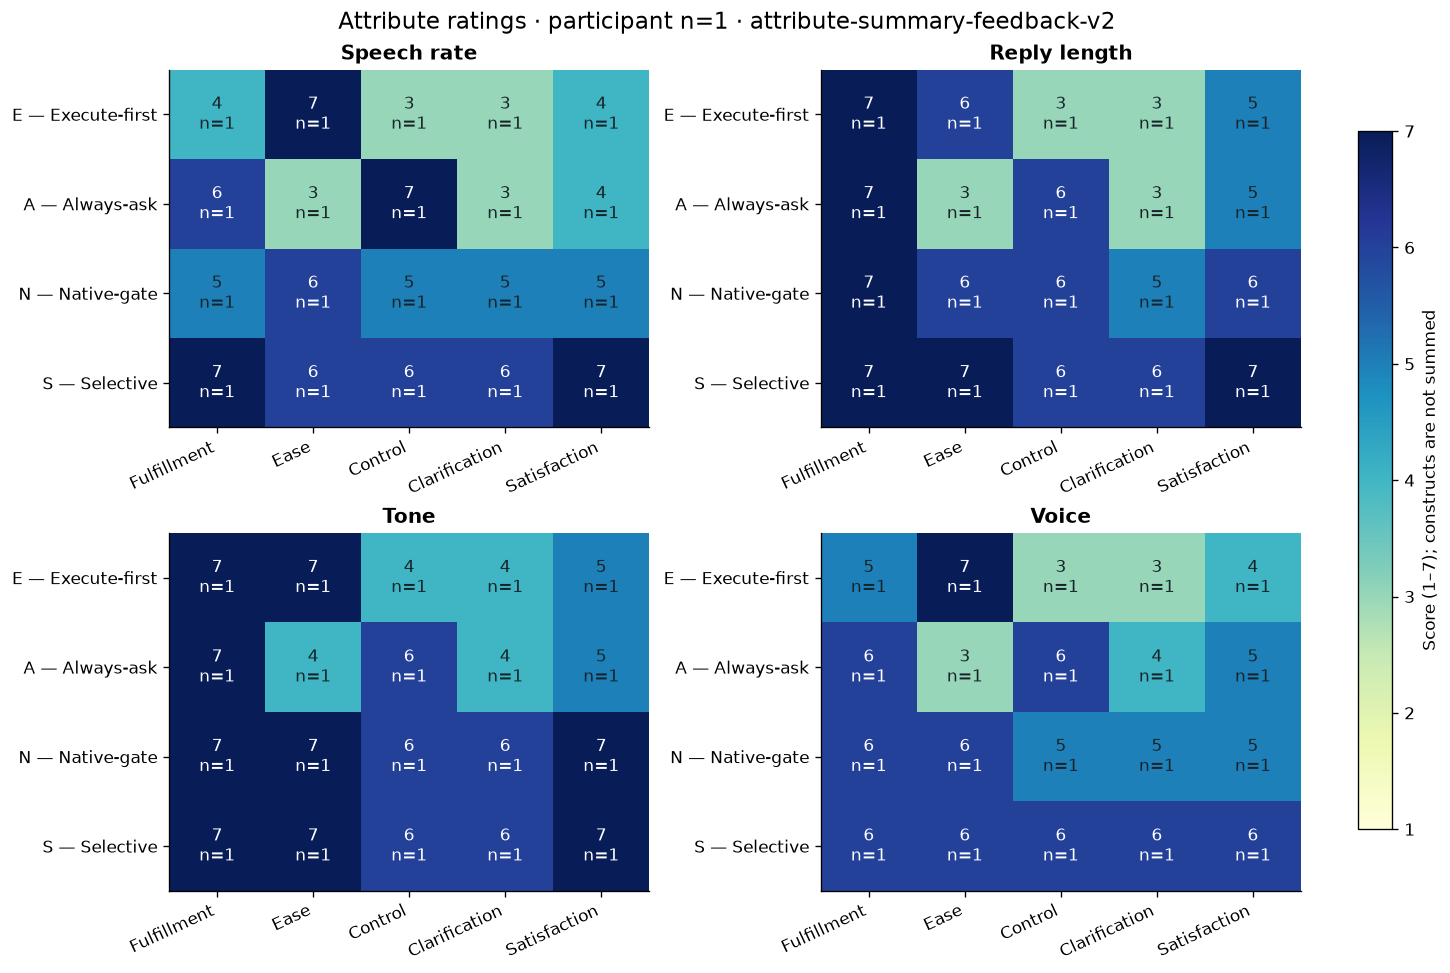

In [3]:
for c in data['cohorts']:
    summary = pd.DataFrame(c['rating_summary'])
    fig, axes = plt.subplots(2,2,figsize=(12,8),layout='constrained')
    for ax, domain in zip(axes.flat, DOMAINS):
        sub = summary[summary.domain.eq(domain)]
        values = sub.pivot(index='condition',columns='item_id',values='mean').reindex(index=CONDITIONS,columns=ITEMS).astype(float)
        counts = sub.pivot(index='condition',columns='item_id',values='n_valid').reindex(index=CONDITIONS,columns=ITEMS)
        cmap = plt.colormaps['YlGnBu'].copy(); cmap.set_bad('#e1e1e1')
        im = ax.imshow(values.to_numpy(),vmin=1,vmax=7,cmap=cmap,aspect='auto')
        ax.set_xticks(range(5),[SHORT[i] for i in ITEMS],rotation=25,ha='right')
        ax.set_yticks(range(4),[f'{s} — {NAMES[s]}' for s in CONDITIONS])
        ax.set_title(DOMAIN_LABELS[domain],weight='bold')
        for row in range(4):
            for col in range(5):
                value, count = values.iloc[row,col], counts.iloc[row,col]
                label = 'missing\nn=0' if pd.isna(value) else f'{value:g}\nn={count}'
                ax.text(col,row,label,ha='center',va='center',color='white' if pd.notna(value) and value>=5.3 else '#17232a',fontsize=10)
    fig.colorbar(im,ax=axes,shrink=.85,label='Score (1–7); constructs are not summed')
    fig.suptitle(f"Attribute ratings · participant n={c['n_participants']} · {c['definition']['source_questionnaire_version']}",fontsize=14)
    plt.show()


## 同一构念内的策略描述对比

每个小图只展示一种构念；横轴为四属性，颜色为策略。点为该格有效评分均值，仅用于描述，不跨构念相加，也不把属性重复测量当作独立样本。有效 n 见热图和汇总文件；当前样本不足以给出总体优越性或显著性结论。

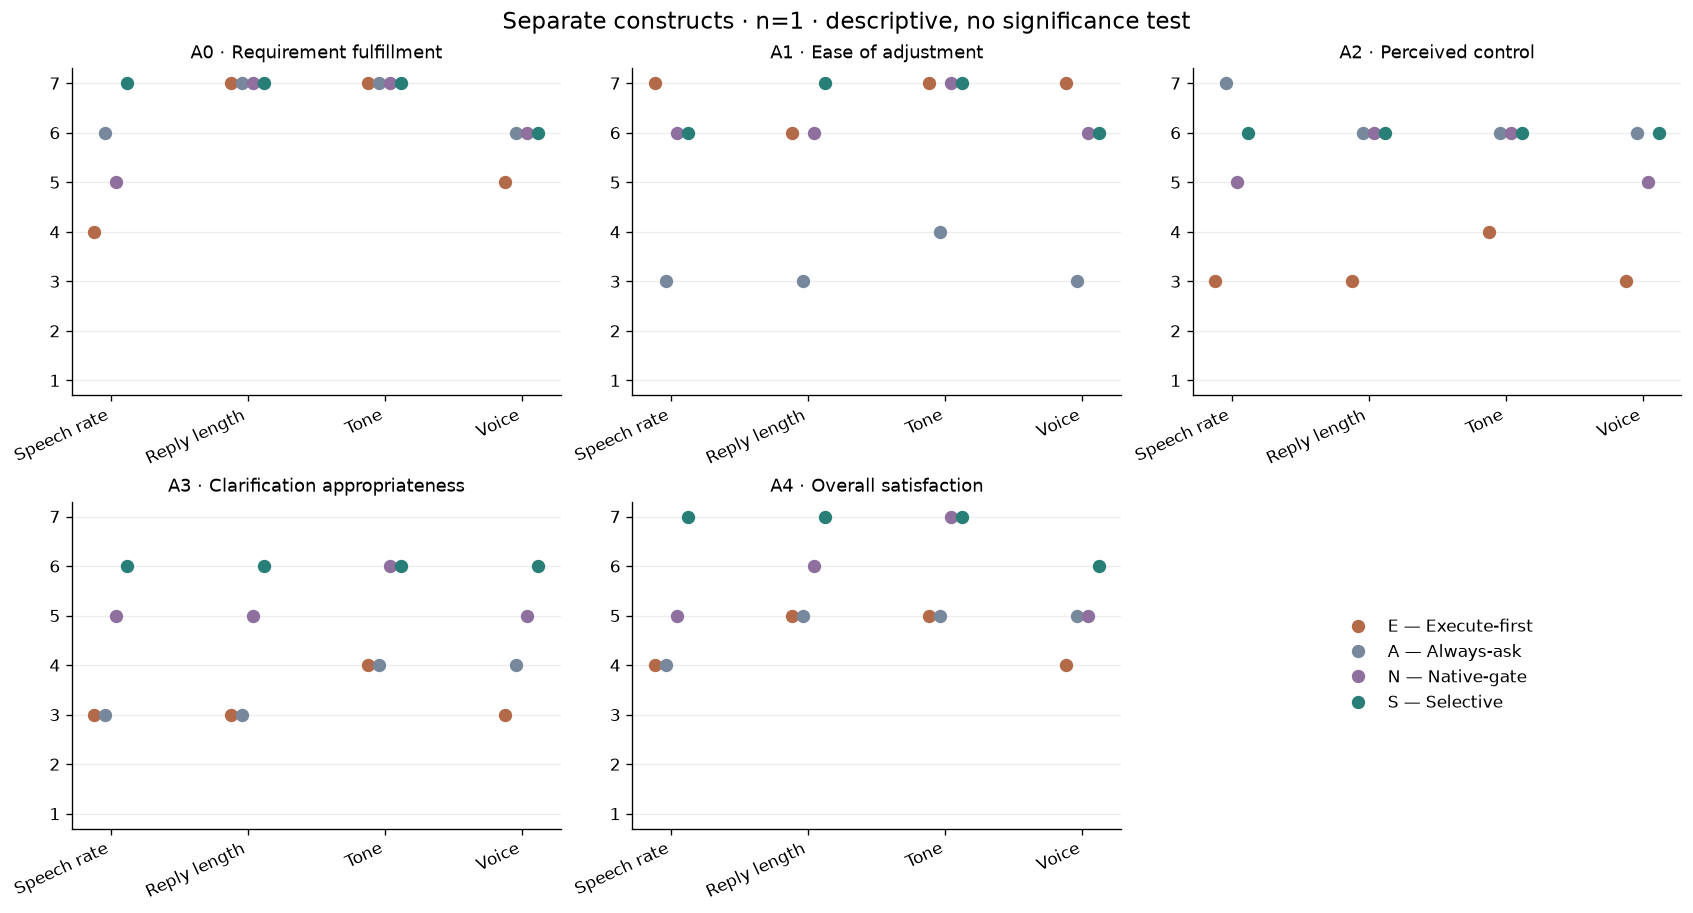

In [4]:
for c in data['cohorts']:
    summary = pd.DataFrame(c['rating_summary'])
    fig, axes = plt.subplots(2,3,figsize=(14,7.5),layout='constrained')
    offsets = [-.12,-.04,.04,.12]
    for ax, item in zip(axes.flat, ITEMS):
        for condition, offset in zip(CONDITIONS,offsets):
            sub = summary[summary.item_id.eq(item)&summary.condition.eq(condition)].set_index('domain').reindex(DOMAINS)
            ax.plot(np.arange(4)+offset,sub['mean'],marker='o',linestyle='none',color=COLORS[condition],label=f'{condition} — {NAMES[condition]}',markersize=7)
        ax.set_xticks(range(4),[DOMAIN_LABELS[d] for d in DOMAINS],rotation=25,ha='right')
        ax.set_ylim(.7,7.3); ax.set_yticks(range(1,8)); ax.grid(axis='y',alpha=.22)
        ax.set_title(f'{item} · {data["constructs"][item]}',fontsize=11)
    axes.flat[5].axis('off')
    handles, labels = axes.flat[0].get_legend_handles_labels()
    axes.flat[5].legend(handles,labels,loc='center',frameon=False)
    fig.suptitle(f"Separate constructs · n={c['n_participants']} · descriptive, no significance test",fontsize=14)
    plt.show()


## 属性内策略偏好

P001 的 tone 修改只作用于该参与者该属性：N、S 各得1票。其它无法判断回答不会据此自动变成多选。No preference 与策略选项互斥；若没有可用偏好则报告缺失，不算作任何策略的0分评分。

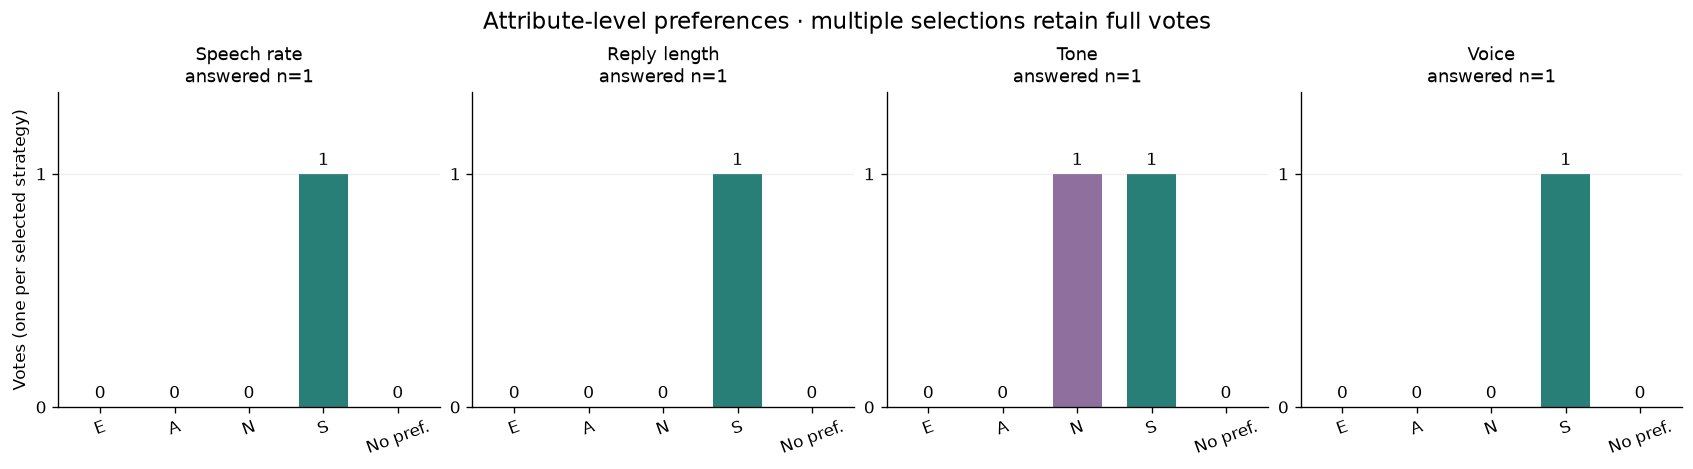

In [5]:
for c in data['cohorts']:
    prefs = {p['domain']:p for p in c['preference_summary']}
    fig, axes = plt.subplots(1,4,figsize=(14,3.8),layout='constrained')
    options = CONDITIONS+['no_preference']
    for ax, domain in zip(axes,DOMAINS):
        p = prefs[domain]
        votes = [p['votes'][s] for s in options]
        bars = ax.bar(range(5),votes,color=[COLORS[s] for s in CONDITIONS]+['#cccccc'],width=.66)
        ax.bar_label(bars,padding=3,fontsize=10)
        ax.set_xticks(range(5),['E','A','N','S','No pref.'],rotation=20)
        ax.set_ylim(0,max(1,c['n_participants'])+.35)
        ax.set_yticks(range(c['n_participants']+1))
        ax.set_title(f"{DOMAIN_LABELS[domain]}\nanswered n={p['n_answered']}",fontsize=11)
        ax.grid(axis='y',alpha=.2)
    axes[0].set_ylabel('Votes (one per selected strategy)')
    fig.suptitle('Attribute-level preferences · multiple selections retain full votes',fontsize=14)
    plt.show()


## 解释边界与下一次更新

本文件展示的是此批刺激材料下的个人主观反馈，不将评分推断为逐任务失败标签；配置错误与听感判断须结合原始回复及实际试听另行检查。没有因修复程序而重写既有评分，也没有由助手补填缺失分数。

导入新参与者后，先运行 `aggregate_results.py` 再运行 `execute_notebook.py`。同一下载再次导入是幂等操作；同一编号内容冲突会被拒绝。v3 多选问卷与原 v2 数据保持独立 cohort。若未来需要合并版本，须明确论证量表及偏好测量等价性，不能自动混合。
